# Clustering WPT packets with k-means
Here we use entropy, kurtosis and skewness for k-means clustering and thresholding.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:

%matplotlib inline
sys.path.append("..")
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.training_data as train

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Parameters

Specify parameters for synthetic data and wavelet transform

In [3]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [0.4, 1]  # amplitude of each sine wave
frequencies = [5, 13]  # frequency content of signal
phases = [0, np.deg2rad(45)]  # phase of each sine wave

duration = 300 / min(frequencies)  # duration of wave

trans_amp = [2 for _ in range(3)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.1

wavelet = "db20"
levels = 3
mode = "symmetric"

fft_lim = 50  # increase value to view more of the fft plots

### Generating synthetic data

Generate synthetic data with transients, noise, and harmonics. Plot the data with its FFT. 

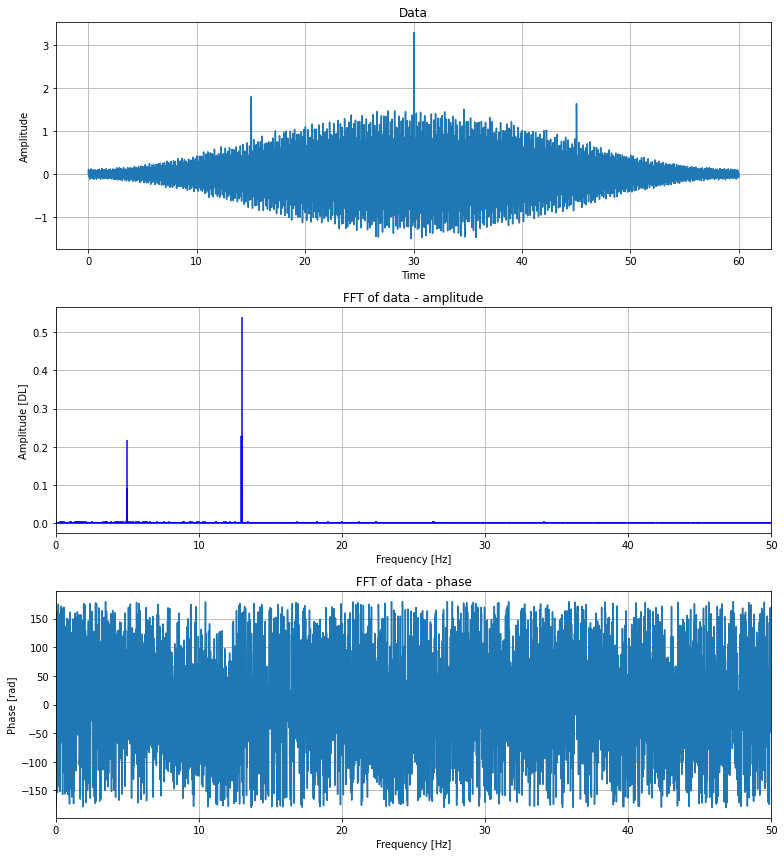

In [4]:
# generate sound wave

data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
transient_signal = sd.transients(
    trans_amp, trans_time, trans_dur, duration, sampling_rate
)
data += transient_signal
data += sd.noise(std_noise, duration, sampling_rate)
data *= np.hamming(signal_length)

fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

Calculating crest factor and energy

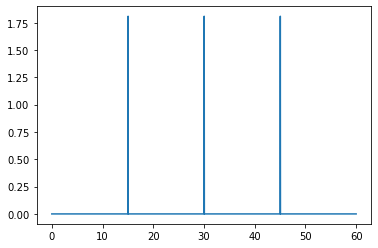

In [5]:
plt.plot(t_plot, transient_signal)
plt.show()

Wavelet transform

In [6]:
wpt_df, tr_ob = train.generate_training_data(data, levels, wavelet, mode, include_tr_ob=True)

In [7]:
wpt_df.head()

,node,energy,kurtosis,crest,entropy,skewness
0,<wavelet_transform.wpt.transform_node.Node obj...,0.252122,3.505964,-0.791053,5.789817,0.122483
1,<wavelet_transform.wpt.transform_node.Node obj...,0.530886,2.980308,-5.251299,5.829109,-0.029309
3,<wavelet_transform.wpt.transform_node.Node obj...,1.009511,2.910209,-4.841918,5.842338,-0.013253
2,<wavelet_transform.wpt.transform_node.Node obj...,0.005538,14.879882,3.361511,4.962886,1.141134
6,<wavelet_transform.wpt.transform_node.Node obj...,0.003841,5.916828,-0.967662,5.411031,0.155427


<AxesSubplot:xlabel='entropy', ylabel='crest'>

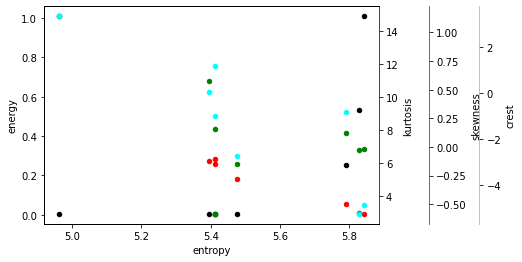

In [8]:
ax_df1 = wpt_df.plot.scatter(x='entropy',y='energy',c='black')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.0))
ax_df2.spines['right'].set_edgecolor('red')
wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='kurtosis',c='red')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.15))
ax_df2.spines['right'].set_edgecolor('green')
wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='skewness',c='green')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.3))
ax_df2.spines['right'].set_edgecolor('cyan')
wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='crest',c='cyan')

<AxesSubplot:xlabel='kurtosis', ylabel='crest'>

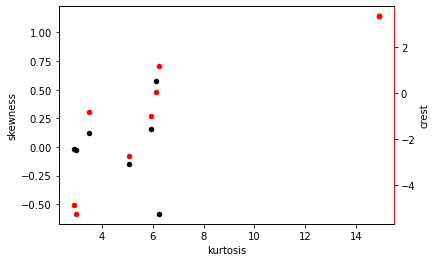

In [9]:
ax_df1 = wpt_df.plot.scatter(x='kurtosis',y='skewness',c='black')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.0))
ax_df2.spines['right'].set_edgecolor('red')
wpt_df.plot.scatter(ax=ax_df2, x='kurtosis',y='crest',c='red')

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

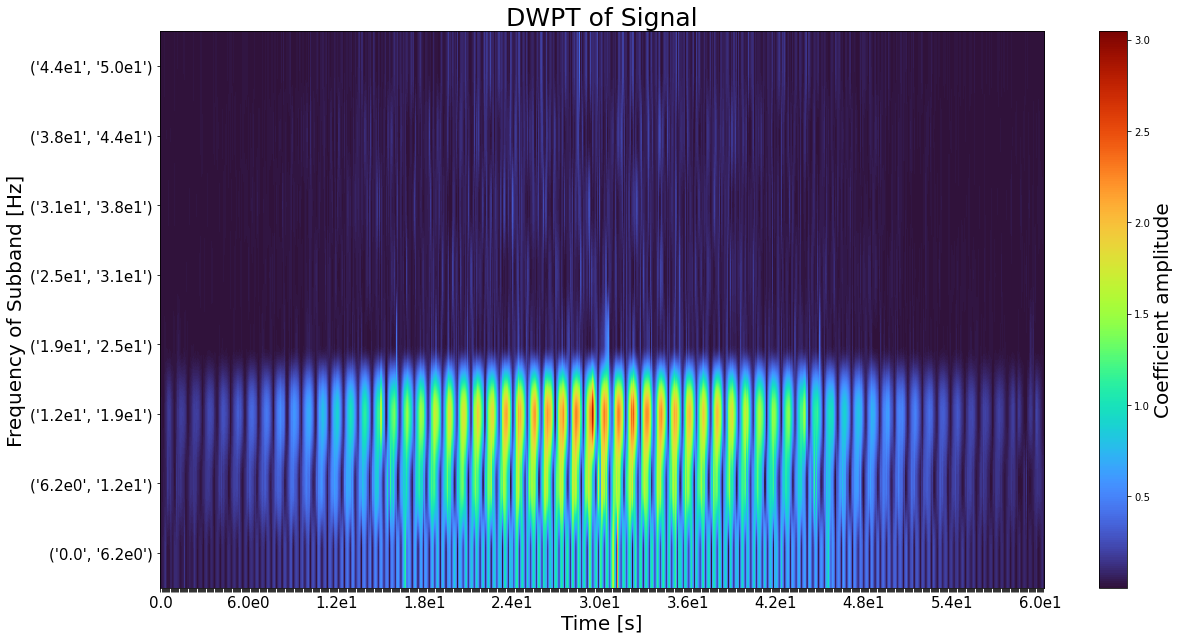

In [10]:
tr_ob.calc_frequencies(sampling_rate)
plot.heisenberg(tr_ob, max(t_plot))

<AxesSubplot:>

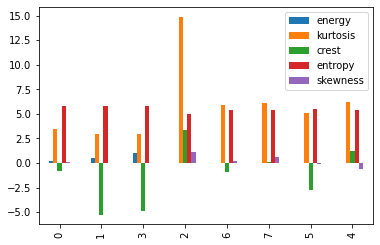

In [11]:
wpt_df.plot.bar()

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

In [12]:
from sklearn import metrics
from collections import defaultdict
from time import time
evaluations = []
evaluations_std = []


def fit_and_evaluate(km, labels, X, name=None, n_runs=5):
    name = km.__class__.__name__ if name is None else name

    train_times = []
    scores = defaultdict(list)
    for seed in range(n_runs):
        km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)
        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(
            metrics.adjusted_rand_score(labels, km.labels_)
        )
        scores["Silhouette Coefficient"].append(
            metrics.silhouette_score(X, km.labels_, sample_size=2000)
        )
    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name,
        "train_time": train_times.mean(),
    }
    evaluation_std = {
        "estimator": name,
        "train_time": train_times.std(),
    }
    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)


In [13]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
classifying_metrics = ["energy", "crest", "kurtosis", "entropy"]
data_train = wpt_df[classifying_metrics]

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 3
kmeans_params = {"init":"k-means++",
    "n_init":10,
    "max_iter":100,
    "tol":1e-8,
    "verbose":0,
    "algorithm":"elkan",
    }

kmeans = KMeans(n_clusters=no_clusters,**kmeans_params)
data_train_predict = kmeans.fit_predict(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
print(kmeans.cluster_centers_)
print(kmeans.n_iter_)
# centers = kmeans.cluster_centers_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

[[-0.50158165  0.21774968 -0.16103912 -0.06452208]
 [ 1.57431276 -1.38212347 -0.8312655   1.149856  ]
 [-0.64071727  1.67549853  2.46772662 -1.97710161]]
2


In [14]:
data_train_predict

array([0, 1, 1, 2, 0, 0, 0, 0])

In [15]:
cluster_ids, cluster_sizes = np.unique(kmeans.labels_, return_counts=True)
print(f"Number of elements assigned to each cluster: {cluster_sizes}")
print(f"cluster IDs: {cluster_ids}")

Number of elements assigned to each cluster: [5 2 1]
cluster IDs: [0 1 2]


In [16]:
fit_and_evaluate(kmeans, labels, data_train_normalised ,name='wpt data')

clustering done in 0.02 ± 0.00 s 
Homogeneity: 1.000 ± 0.000
Completeness: 1.000 ± 0.000
V-measure: 1.000 ± 0.000
Adjusted Rand-Index: 1.000 ± 0.000
Silhouette Coefficient: 0.489 ± 0.000


3 clusters:

- high energy, low kurtosis, low skewness -> harmonic
- low energy, high kurtosis, high skewness -> transient
- low energy, medium kurtosis, low skewness -> noise

### Plot result

Plot the assigned group against the frequency of the node. 

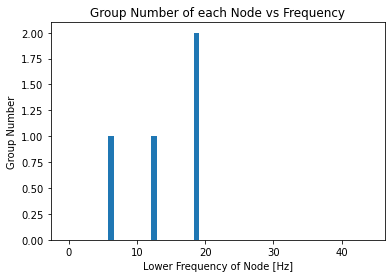

In [17]:
# plot regular k-means
plt.bar([node.frequency_range[0] for node in wpt_df["node"]], labels)
plt.title("Group Number of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Group Number")
plt.show()

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [18]:
# apply PCA to training data
pca = PCA(n_components=3)#data_train.shape[1])
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters,**kmeans_params)
data_train_predict_pca = kmeans_pca.fit_predict(data_pca)

# convert centres back to regular feature space (energy, kurtosis, crest, etc.)
labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(
    pca.inverse_transform(kmeans_pca.cluster_centers_)
)

In [19]:
kmeans_pca.cluster_centers_

array([[-2.44512459,  0.63942324, -0.11919384],
       [ 0.29034867, -0.49013749,  0.06001917],
       [ 3.43850583,  1.17184096, -0.06170817]])

<AxesSubplot:xlabel='principal component 1', ylabel='principal component 3'>

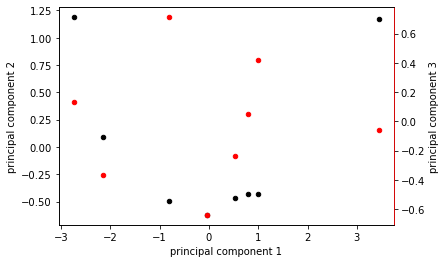

In [20]:
PC_df = pd.DataFrame(data = pca.transform(data_train_normalised)
             , columns = ['principal component 1', 'principal component 2', 'principal component 3'])

ax_pca_df1 = PC_df.plot.scatter(x='principal component 1',y='principal component 2', c='black')

ax_pca_df2 = ax_pca_df1.twinx()
ax_pca_df2.spines['right'].set_position(('axes', 1.0))
ax_pca_df2.spines['right'].set_edgecolor('red')
PC_df.plot.scatter(ax=ax_pca_df2, x='principal component 1',y='principal component 3', c='red')

### Plot PCA result

The group number vs frequency for each node is plotted again after PCA is applied.

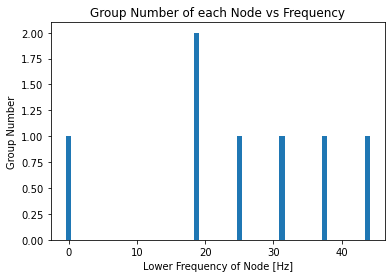

Eigenvectors:
energy, kurtosis, skewness
[[-0.45  0.52  0.5  -0.53]
 [ 0.81 -0.03  0.56 -0.18]
 [ 0.25  0.84 -0.19  0.43]]
Eigenvalues: [3.78 0.57 0.19]


In [21]:
# plot pca k-means
lower_freqs = [node.frequency_range[0] for node in wpt_df["node"]]
plt.bar([node.frequency_range[0] for node in wpt_df["node"]], labels_pca)
plt.tick_params
plt.title("Group Number of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Group Number")
plt.show()

eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

print("Eigenvectors:")
print("energy, kurtosis, skewness")
print(np.round(eigenvectors, 2))

print("Eigenvalues:", np.round(eigenvalues, 2))

### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

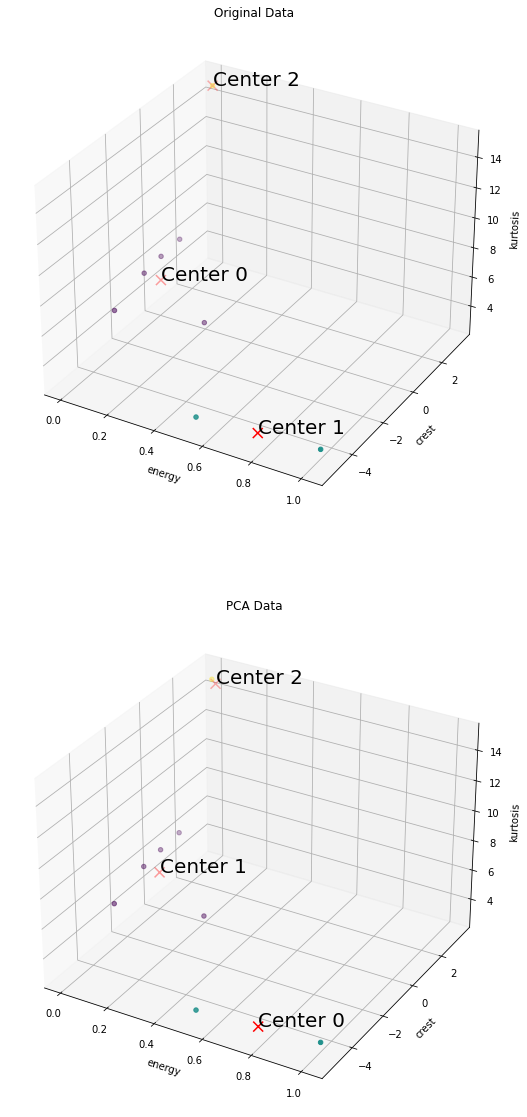

In [22]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={"projection": "3d"})

titles = ["Original Data", "PCA Data"]

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap("Set1")
    if i == 0:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers
        labels_scatter = labels.copy()
        color_map_labels = data_train_predict
    else:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers_pca
        labels_scattetr = labels_pca.copy()
        color_map_labels = data_train_predict

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        # c=[cmap(label) for label in labels_scatter],
        c=color_map_labels
    )
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c="red",
        marker="x",
        s=100,
    )

    ax.set_xlabel(data_train.columns[0])
    ax.set_ylabel(data_train.columns[1])
    ax.set_zlabel(data_train.columns[2])
    ax.set_title(titles[i])

    # Annotate cluster centers with their positions
    for i, center in enumerate(centers_scatter):
        ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

plt.show()

### Results

Plotting the reconstructed waves at each node alongside their assigned group number (non-pca).

Reconstructed nodes by group:


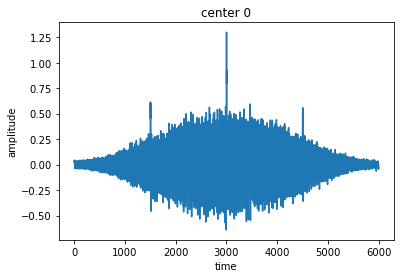

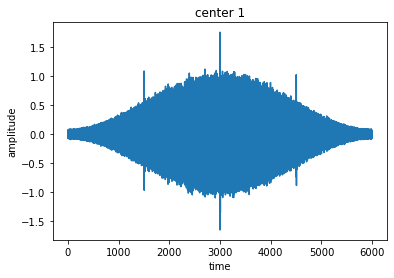

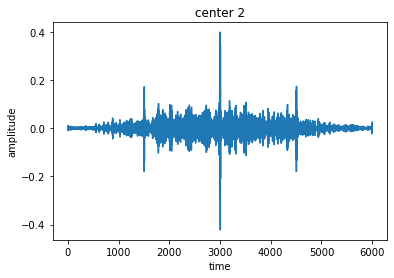

In [23]:
plot.plot_reconstructions_by_group(tr_ob, labels, no_clusters, order="freq")

[0 1 1 2 0 0 0 0]


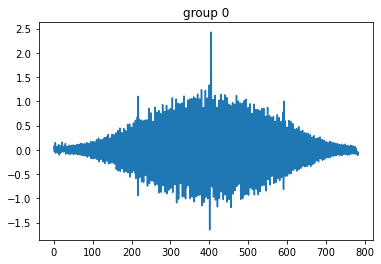

0.2521220895187001


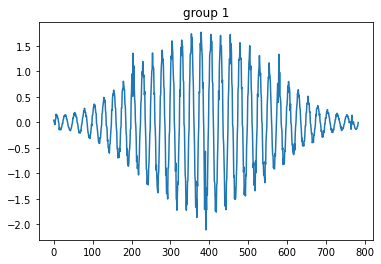

0.53088571971074


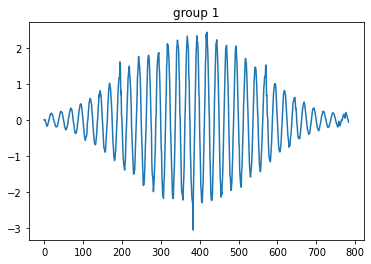

1.0095108956337335


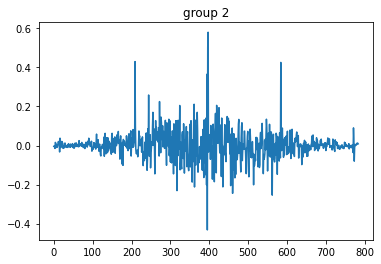

0.005538485434814231


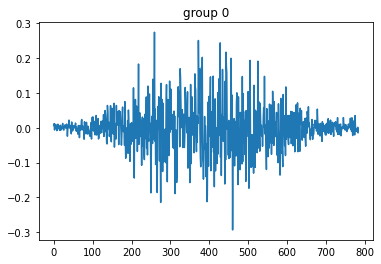

0.003841005013650188


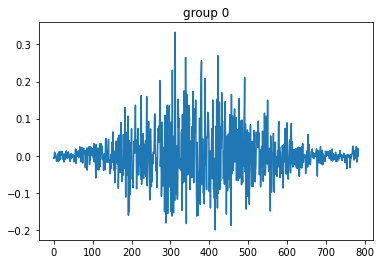

0.0038955926995838017


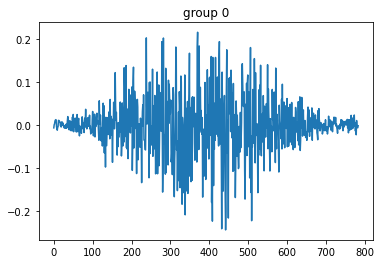

0.0040043918805859995


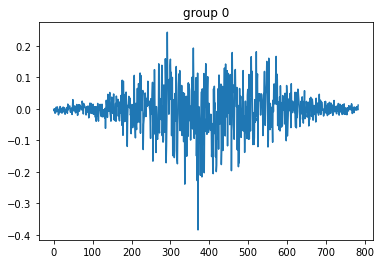

0.003987298105928288


In [24]:
# Plot each node 
print(labels)
for i, node in enumerate(tr_ob.get_level(order="freq")):
    plt.plot(node.data)
    plt.title(f"group {labels[i]}")
    plt.show()
    print(node.energy)